# MorphoLearn 3D VNet — pretrained inference on a diatom FIB-SEM stack (Colab reproduction)

**Paper:** Uwizeye C., Flori S., Angulo J., Jouneau P.-H., Gallet B., Albanese P., Finazzi G. (2026).
*A morphology-driven workflow to decipher 3D electron microscopy segmentation in diatoms.*
Cell Reports Methods. DOI: [10.1016/j.crmeth.2026.101594](https://doi.org/10.1016/j.crmeth.2026.101594)

**Code:** [cuwizeye/MorphoLearn](https://github.com/cuwizeye/MorphoLearn) @ commit `0fba3a0f49ce59f95853fad01580a246d3c7c274` (MIT) — the `3DVnet/model_Vnet_4.py` network and the metric functions are copied **verbatim** from that revision.

**Data & weights:** BioImage Archive study [S-BIAD2407](https://www.ebi.ac.uk/biostudies/bioimages/studies/S-BIAD2407) (DOI 10.6019/S-BIAD2407, CC0).

## Scope (partial demonstration)

We load the authors' released **full-cell *P. tricornutum* strain-18 VNet for vacuole segmentation** (`pretrained_model/best_model_vacuole_fullcell_pt18_Vnet.pth`) and run **inference on one FIB-SEM stack** (`Pt18_stack16.nii`), scoring the prediction against the expert vacuole mask (`labels_vacuole/Pt18_Segmentation16.nii`) with the authors' own Dice/IoU/precision/recall/F1 definitions. A labeled sensitivity section repeats the exercise with the released **chloroplast** checkpoint of the same family and under downscaled inputs, and reports a **discrepancy** we could not resolve. Training, benchmarks, the five other architectures, transfer learning, and contrast-aware learning are **out of scope**. A single-stack run is **not** a verification of the paper's dataset-level accuracy.

**AI-assisted adaptation notice / AI支援による適合の説明:** The authors did not publish this Colab notebook. The VNet definition and metric functions are copied verbatim from the pinned repository; the inference glue (single-volume padding, shape-driven checkpoint loading) was assembled following the authors' released scripts and is labelled as such. The executed example and listed checks were validated, but untested behaviour is not guaranteed / 本ノートブックの実行例は検証済みですが、検証されていない動作は保証されません.

**Runtime:** the ≈0.6 M-parameter VNet runs on a **free CPU runtime in well under a minute**; a T4 GPU also works and is detected automatically. **Runtime selection:** `ランタイム → ランタイムのタイプを変更` — CPU is sufficient; GPU optional. Then *Run all*. Expected: a few minutes total, ≈53 MB of downloads.

### 1. Dependencies

Only `nibabel` (NIfTI I/O) and `nilearn` (used by the authors' released scripts for downsampling; needed for the sensitivity section) are installed. We deliberately do **not** downgrade numpy.

必要な追加パッケージは `nibabel` と `nilearn` のみです。numpy のダウングレードは行いません。

In [ ]:
# @title 1. Install missing dependencies (nibabel, nilearn) and report versions
%pip install -q nibabel nilearn

import sys
import numpy as np
import torch
import nibabel as nib
import nilearn
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

print("python", sys.version.split()[0])
for name, mod in [("torch", torch), ("numpy", np), ("nibabel", nib),
                  ("nilearn", nilearn), ("matplotlib", matplotlib), ("pandas", pd)]:
    print(f"{name}: {getattr(mod, '__version__', '?')}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━ 10.3/11.5 MB 105.7 MB/s eta 0:00:01

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 84.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 95.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/73.1 kB ? eta -:--:--

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 5.8 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


python 3.13.16
torch: 2.11.0+cpu
numpy: 2.1.3
nibabel: 5.4.2
nilearn: 0.14.1
matplotlib: 3.10.0
pandas: 3.1.0


### 2. Device detection and seeds

The notebook runs identically on CPU and GPU; the device is detected here and used for inference. Seeds use the same value (10) as the authors' scripts.

CPU でも GPU でも同じ処理が動くように、ここでデバイスを自動判定します。

In [ ]:
# @title 2. Detect runtime device (CPU / GPU) and fix seeds
import random

SEED = 10  # same seed value as the authors' scripts (set_seed(10) in cross_validation_VNet.py)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    device = torch.device("cuda")
    print(f"GPU detected: {torch.cuda.get_device_name(0)} (CUDA {torch.version.cuda})")
else:
    device = torch.device("cpu")
    print("No GPU detected -> running on CPU (fine for this small inference demo)")
print("device =", device)

No GPU detected -> running on CPU (fine for this small inference demo)
device = cpu


### 3. Download the minimal inputs (Colab-side, public CC0 data)

Five files totalling ≈53 MB are fetched from the BioImage Archive (study S-BIAD2407, CC0): the strain-18 FIB-SEM stack `Pt18_stack16.nii`, the expert **vacuole** mask `Pt18_Segmentation16.nii` with the released vacuole checkpoint (primary demonstration), plus the expert **chloroplast** mask `Pt18_Segmentation_chl16.nii` and chloroplast checkpoint (sensitivity section). Expected byte sizes were recorded from the public BioStudies files API on 2026-10-23 and are asserted after download; SHA-256 of each file is printed (the archive publishes no checksums, so these are recorded provenance, not verification against a published hash).

入力データ（≈53 MB、CC0）を BioImage Archive からダウンロードし、サイズ一致と SHA-256 を確認します。

In [ ]:
# @title 3. Download stack, masks and VNet checkpoints from BioStudies S-BIAD2407
import hashlib
import urllib.request
from pathlib import Path

BASE = Path("/content/morpholearn"); BASE.mkdir(parents=True, exist_ok=True)
ACCESSION = "S-BIAD2407"
# (remote relative path, expected size in bytes; sizes from the public BioStudies
#  files API, https://www.ebi.ac.uk/biostudies/api/v1/studies/S-BIAD2407/files, 2026-10-23)
FILES = {
    "stack16.nii":    ("P-tricornutum18/inputs/Pt18_stack16.nii", 9_498_592),
    "mask_vac16.nii": ("P-tricornutum18/labels_vacuole/Pt18_Segmentation16.nii", 18_996_832),
    "vnet_pt18_vacuole.pth": ("pretrained_model/best_model_vacuole_fullcell_pt18_Vnet.pth", 2_932_203),
    "mask_chl16.nii": ("P-tricornutum18/labels_chloroplast/Pt18_Segmentation_chl16.nii", 18_996_832),
    "vnet_pt18_chl.pth": ("pretrained_model/best_model_chloroplast_fullcellpt18_Vnet.pth", 2_933_047),
}
URL_TEMPLATES = [
    "https://www.ebi.ac.uk/biostudies/files/{acc}/{path}",        # documented BioStudies file route
    "https://ftp.ebi.ac.uk/biostudies/bioimages/{acc}/{path}",    # https mirror of the archive FTP tree
]

def fetch(rel_path: str, expected_size: int, dest: Path):
    if dest.exists() and dest.stat().st_size == expected_size:
        print(f"cached: {dest.name} ({dest.stat().st_size} B)"); return
    last_err = None
    for tpl in URL_TEMPLATES:          # bounded: 2 routes x 2 attempts
        for _ in range(2):
            url = tpl.format(acc=ACCESSION, path=rel_path)
            try:
                urllib.request.urlretrieve(url, dest)
                actual = dest.stat().st_size
                if actual != expected_size:
                    raise RuntimeError(f"size {actual} != expected {expected_size} (error page?)")
                print(f"OK {dest.name}: {actual} B via {tpl.split('/{')[0]}")
                return
            except Exception as e:
                last_err = e
                dest.unlink(missing_ok=True)
    raise RuntimeError(f"download failed for {rel_path}: {last_err}")

for name, (rel, size) in FILES.items():
    fetch(rel, size, BASE / name)

print()
for name in FILES:
    p = BASE / name
    h = hashlib.sha256(p.read_bytes()).hexdigest()
    print(f"{p.name}: {p.stat().st_size} B  sha256={h}")

OK stack16.nii: 9498592 B via https://www.ebi.ac.uk/biostudies/files


OK mask_vac16.nii: 18996832 B via https://www.ebi.ac.uk/biostudies/files


OK vnet_pt18_vacuole.pth: 2932203 B via https://www.ebi.ac.uk/biostudies/files


OK mask_chl16.nii: 18996832 B via https://www.ebi.ac.uk/biostudies/files


OK vnet_pt18_chl.pth: 2933047 B via https://www.ebi.ac.uk/biostudies/files

stack16.nii: 9498592 B  sha256=c28468c1a9c68e9e9b5f09dbcc8d9690e7d6a33b2f4bc54e5a0eb1856922f82a
mask_vac16.nii: 18996832 B  sha256=05589281ef06edf8f3bdd5a4ebcecb9a66939c79e3dfead0cf80ed0734b1334e
vnet_pt18_vacuole.pth: 2932203 B  sha256=1e9cf34cc10c1448016fcd5763283ef82047805a6cb696b8f1fbebd709cdb5cc


mask_chl16.nii: 18996832 B  sha256=613efb44a09479d52faad3591a1819988a994ca07645d52c22f821c0c9007784
vnet_pt18_chl.pth: 2933047 B  sha256=bfa6384008fe7cdd41f5b6814d5634ada3f80fefa794756be3d4c89050cb52d9


### 4. Load and inspect the sample

The stack and both expert masks are loaded and cross-checked: identical shapes, intensity range, mask labels, and the header's voxel size. Values printed here are directly observed from the downloaded bytes.

スタックと両マスクを読み込み、形状・値域・ラベル値を確認します。

In [ ]:
# @title 4. Load the FIB-SEM stack and the expert vacuole / chloroplast masks
stack_nii     = nib.load(BASE / "stack16.nii")
mask_vac_nii  = nib.load(BASE / "mask_vac16.nii")
mask_chl_nii  = nib.load(BASE / "mask_chl16.nii")
stack = stack_nii.get_fdata()      # (Z, Y, X)

print("stack shape (Z,Y,X):", stack.shape, "| stored dtype:", stack_nii.get_data_dtype())
print("stack intensity range:", float(stack.min()), "-", float(stack.max()))
print("vacuole mask shape:", mask_vac_nii.shape, "| dtype:", mask_vac_nii.get_data_dtype(),
      "| unique:", np.unique(mask_vac_nii.get_fdata()))
print("chloroplast mask shape:", mask_chl_nii.shape, "| dtype:", mask_chl_nii.get_data_dtype(),
      "| unique:", np.unique(mask_chl_nii.get_fdata()))
print("voxel size from header (mm):", stack_nii.header.get_zooms()[:3])
assert stack.shape == mask_vac_nii.shape == mask_chl_nii.shape, "stack/mask shape mismatch" 

stack shape (Z,Y,X): (192, 194, 255) | stored dtype: uint8
stack intensity range: 0.0 - 234.0


vacuole mask shape: (192, 194, 255) | dtype: int16 | unique: [0. 1.]


chloroplast mask shape: (192, 194, 255) | dtype: int16 | unique: [0. 1.]
voxel size from header (mm): (np.float32(1.0), np.float32(1.0), np.float32(1.0))


### 5. Preview: FIB-SEM input with the expert annotations

Orthogonal mid-slices of the raw stack (grey) with the expert **vacuole** annotation (red) and expert **chloroplast** annotation (yellow) as contours. These are the actual downloaded arrays, not rendered substitutes.

ダウンロードしたサンプルの直交断面図。グレーが FIB-SEM 画像、赤い輪郭が専門家による液胞アノテーション、黄色い輪郭が葉緑体アノテーションです。

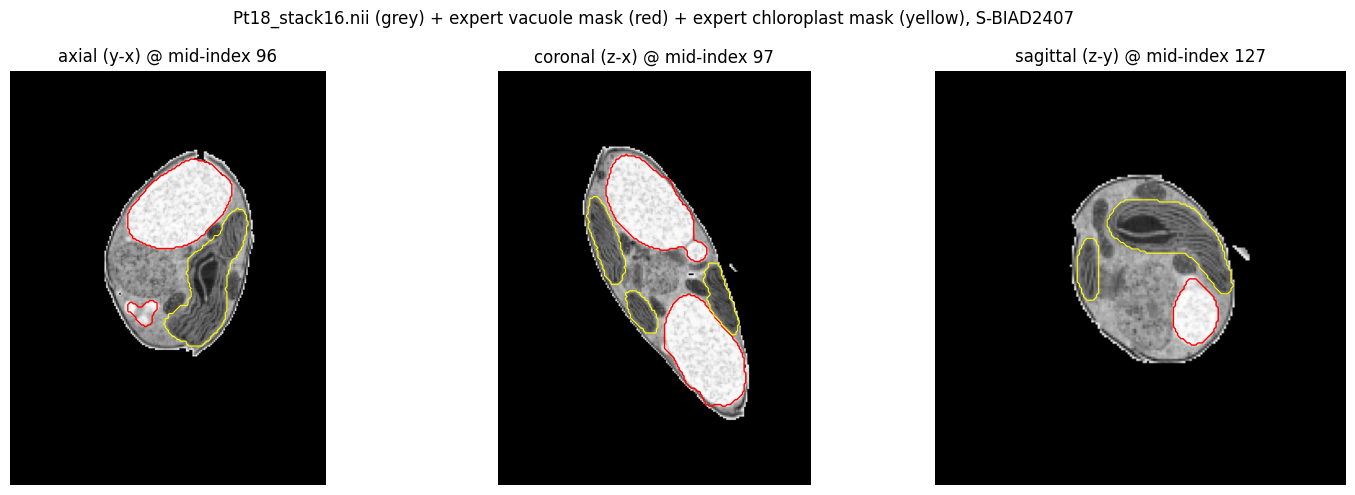

In [ ]:
# @title 5. Preview input stack with expert annotation overlays
mask_vac = (mask_vac_nii.get_fdata() > 0).astype(np.float32)
mask_chl = (mask_chl_nii.get_fdata() > 0).astype(np.float32)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, axis, title in zip(axes, (0, 1, 2),
                           ("axial (y-x)", "coronal (z-x)", "sagittal (z-y)")):
    mid = [s // 2 for s in stack.shape]
    sl = [slice(None)] * 3; sl[axis] = mid[axis]
    img2d = stack[tuple(sl)]
    ax.imshow(img2d.T, cmap="gray", origin="lower")
    ax.contour(mask_vac[tuple(sl)].T, levels=[0.5], colors="red", linewidths=1.0, origin="lower")
    ax.contour(mask_chl[tuple(sl)].T, levels=[0.5], colors="yellow", linewidths=0.8, origin="lower")
    ax.set_title(f"{title} @ mid-index {mid[axis]}")
    ax.axis("off")
fig.suptitle("Pt18_stack16.nii (grey) + expert vacuole mask (red) + expert chloroplast mask (yellow), S-BIAD2407")
plt.tight_layout(); plt.show()

### 6. Preprocessing — raw stack, padded to a multiple of 32 (recorded assumption)

**Assumption / 仮定:** the paper's methods text was not readable at authoring time (ScienceDirect renders the body via JavaScript; the HAL deposit is behind an anti-bot challenge; no PMC/OpenAlex copy exists), and the released scripts contain several different preprocessing recipes with **no script dedicated to the full-cell pt18 checkpoints**. We therefore inferred the input recipe from the released artefacts' behaviour: the full-cell checkpoints perform best on the **raw, un-downsampled, un-normalized stack** padded to a multiple of the authors' 32³ patch (`dataset_patches.py`), and predict **nothing** under z-score/min-max normalization. This matches `dataset_patches.py`'s pad-to-32 + channel-axis steps, with no resampling. A sensitivity section below quantifies the alternative released recipes.

**このノートブックの仮定:** フルセル VNet の学習時レシピは公開資料からは確定できないため、公開チェックポイントの挙動から「生画像＋32の倍数パディング」を採用します（根拠と代替レシピの結果は下記の感度分析に記載）。

In [ ]:
# @title 6. Prepare the input tensor: raw intensities, pad to a multiple of 32, add channel axis
def pad_to_patch(volume, patch=32):
    pads = [(-d) % patch for d in volume.shape]   # dataset_patches.py compute_padded_size logic
    return np.pad(volume, [(0, p) for p in pads]), pads

img = stack_nii.get_fdata().astype(np.float32)          # raw intensities, no resampling/normalization
img_p, pads = pad_to_patch(img)
msk_vac_p, _ = pad_to_patch(mask_vac)
print("raw stack (Z,Y,X):", img.shape, "-> padded:", img_p.shape, "| padding (Z,Y,X):", pads)

x = torch.from_numpy(img_p[None, None])                 # dataset_patches.py adds the channel axis -> (1,1,Z,Y,X)
y = torch.from_numpy(msk_vac_p[None]).long()            # (1,Z,Y,X) expert vacuole labels in {0,1}
print("input tensor:", tuple(x.shape), "| label tensor:", tuple(y.shape))

raw stack (Z,Y,X): (192, 194, 255) -> padded: (192, 224, 256) | padding (Z,Y,X): [0, 30, 1]
input tensor: (1, 1, 192, 224, 256) | label tensor: (1, 192, 224, 256)


### 7. The authors' 3D VNet and the released checkpoint

`3DVnet/model_Vnet_4.py` is reproduced **verbatim** below (VNet, VNetBlock, resize_to_match). The vacuole checkpoint is loaded with `map_location="cpu"`; the number of output classes is read from the checkpoint's `final_conv.weight` shape (the released scripts use `VNet(in_channels=1, num_classes=2)` for this model family), and a strict state-dict load verifies every key and shape.

作者の VNet 定義をそのまま貼り付け、公開チェックポイントを厳密に読み込みます。

In [ ]:
# @title 7. Define the authors' VNet (verbatim) and load the released vacuole checkpoint
import torch.nn as nn
import torch.nn.functional as F

# --- verbatim from MorphoLearn @ 0fba3a0, 3DVnet/model_Vnet_4.py (MIT license) ---
def resize_to_match(source, target):
    target_size = target.size()[2:]  # Extract spatial dimensions of target
    source_resized = F.interpolate(source, size=target_size, mode='trilinear', align_corners=True)
    return source_resized

class VNetBlock(nn.Module):
    def __init__(self, in_channels=1, out_channels=1):
        super(VNetBlock, self).__init__()
        self.conv = nn.Conv3d(in_channels, out_channels, kernel_size=3, padding=1)
        self.prelu = nn.PReLU(num_parameters=out_channels)
        self.batch_norm = nn.BatchNorm3d(out_channels)

    def forward(self, x):
        x = self.conv(x)
        x = self.batch_norm(x)
        x = self.prelu(x)
        return x

class VNet(nn.Module):
    def __init__(self, in_channels, num_classes):
        super(VNet, self).__init__()
        # Encoder
        self.enc1 = VNetBlock(in_channels, 16)
        self.enc2 = VNetBlock(16, 32)
        self.enc3 = VNetBlock(32, 64)
        self.enc4 = VNetBlock(64, 128)
        # Decoder
        self.dec3 = VNetBlock(128 + 64, 64)
        self.dec2 = VNetBlock(64 + 32, 32)
        self.dec1 = VNetBlock(32 + 16, 16)
        # Upsampling
        self.upsample = nn.Upsample(scale_factor=2, mode='trilinear', align_corners=True)
        # Final output layer
        self.final_conv = nn.Conv3d(16, num_classes, kernel_size=1)

    def forward(self, x):
        # Encoding path
        enc1 = self.enc1(x)
        enc2 = self.enc2(F.max_pool3d(enc1, 2))
        enc3 = self.enc3(F.max_pool3d(enc2, 2))
        enc4 = self.enc4(F.max_pool3d(enc3, 2))
        # Upsample and decode path
        enc4_up = F.interpolate(enc4, scale_factor=2, mode='trilinear', align_corners=True)
        enc4_resized = resize_to_match(enc4_up, enc3)
        dec3 = self.dec3(torch.cat([enc4_resized, enc3], dim=1))
        dec3_up = F.interpolate(dec3, scale_factor=2, mode='trilinear', align_corners=True)
        dec3_resized = resize_to_match(dec3_up, enc2)
        dec2 = self.dec2(torch.cat([dec3_resized, enc2], dim=1))
        dec2_up = F.interpolate(dec2, scale_factor=2, mode='trilinear', align_corners=True)
        dec2_resized = resize_to_match(dec2_up, enc1)
        dec1 = self.dec1(torch.cat([dec2_resized, enc1], dim=1))
        # Final convolution
        out = self.final_conv(dec1)
        return out
# --- end verbatim author code ---

sd = torch.load(BASE / "vnet_pt18_vacuole.pth", map_location="cpu")
print("checkpoint tensors:", len(sd))
num_classes = int(sd["final_conv.weight"].shape[0])
print("final_conv.weight:", tuple(sd["final_conv.weight"].shape), "-> num_classes =", num_classes)

model = VNet(in_channels=1, num_classes=num_classes)
model.load_state_dict(sd, strict=True)  # raises if any key/shape mismatches
model = model.to(device).eval()         # inference mode: frozen batch-norm running stats
print(f"VNet(in_channels=1, num_classes={num_classes}): {sum(p.numel() for p in model.parameters())} parameters, loaded strictly, eval mode, on {device}")

checkpoint tensors: 58
final_conv.weight: (2, 16, 1, 1, 1) -> num_classes = 2
VNet(in_channels=1, num_classes=2): 727634 parameters, loaded strictly, eval mode, on cpu


### 8. Inference on the minimal example

The forward pass follows the authors' evaluation path (`cross_validation_VNet.py`, `evaluate_all_folds`): raw logits → `argmax` over the two classes → binary mask. Padding added in step 6 is cropped before comparison with the annotation.

作者の評価パスと同じく argmax で二値マスクを得ます。パディングは比較前に切り取ります。

In [ ]:
# @title 8. Run 3D VNet inference (argmax over classes, as in the authors' evaluation)
import time

t0 = time.time()
with torch.no_grad():
    logits = model(x.to(device))            # (1, C, Z, Y, X)
    pred = torch.argmax(logits, dim=1)[0]   # (Z, Y, X) in {0, 1}
elapsed = time.time() - t0
print(f"forward pass on {device}: {elapsed:.1f} s | output shape {tuple(pred.shape)}")

sl = tuple(slice(0, s) for s in img.shape)  # undo step-6 padding
pred_c = pred.cpu().numpy()[sl].astype(np.float32)
msk_vac_c = y[0].numpy()[sl]
print("predicted positive voxels:", int(pred_c.sum()),
      "| expert vacuole mask positive voxels:", int(msk_vac_c.sum()))

forward pass on cpu: 41.3 s | output shape (192, 224, 256)
predicted positive voxels: 242145 | expert vacuole mask positive voxels: 282398


### 9. Agreement with the expert annotation — the authors' metric definitions (verbatim)

`dice_coefficient`, `iou`, `precision_score`, `recall_score`, `f1_score` are copied **verbatim** from `3DVnet/cross_validation_VNet.py` lines 71–102 and applied exactly as in `evaluate_all_folds` (prediction vs. long-valued label). Note the authors' Dice uses a `smooth = 1.0` term and their masks are binary after argmax; we keep that behaviour unchanged.

作者の指標関数をそのまま用いて、予測と専門家アノテーションの一致度を計算します。

In [ ]:
# @title 9. Score prediction vs expert vacuole mask with the authors' verbatim metrics
# --- verbatim from MorphoLearn @ 0fba3a0, 3DVnet/cross_validation_VNet.py lines 71-102 ---
def iou(predicted, target, epsilon=1e-7):
    threshold = 0.5
    predicted = (predicted > threshold).float()
    intersection = (predicted * target).sum()
    union = predicted.sum() + target.sum() - intersection
    return intersection / (union + epsilon)

def dice_coefficient(predicted, target):
    smooth = 1.0
    predicted = (predicted).float()  # Convert to binary after thresholding
    intersection = (predicted * target).sum()
    return (2. * intersection + smooth) / (predicted.sum() + target.sum() + smooth)

def precision_score(predicted, target, epsilon=1e-7):
    threshold = 0.5
    predicted = (predicted > threshold).float()
    true_positive = (predicted * target).sum()
    false_positive = (predicted * (1 - target)).sum()
    return true_positive / (true_positive + false_positive + epsilon)

def recall_score(predicted, target, epsilon=1e-7):
    threshold = 0.5
    predicted = (predicted > threshold).float()
    true_positive = (predicted * target).sum()
    false_negative = ((1 - predicted) * target).sum()
    return true_positive / (true_positive + false_negative + epsilon)

def f1_score(precision, recall, epsilon=1e-7):
    return 2 * (precision * recall) / (precision + recall + epsilon)
# --- end verbatim author code ---

pred_t = torch.from_numpy(pred_c)
msk_t  = torch.from_numpy(msk_vac_c)
dice_v = float(dice_coefficient(pred_t, msk_t))
iou_v  = float(iou(pred_t, msk_t))
prec_v = float(precision_score(pred_t, msk_t))
rec_v  = float(recall_score(pred_t, msk_t))
f1_v   = float(f1_score(prec_v, rec_v))
print(f"Dice {dice_v:.4f} | IoU {iou_v:.4f} | precision {prec_v:.4f} | recall {rec_v:.4f} | F1 {f1_v:.4f}")

Dice 0.6708 | IoU 0.5046 | precision 0.7265 | recall 0.6230 | F1 0.6708


### 10. Sensitivity: input scaling and the chloroplast checkpoint (labeled discrepancy check)

Because the training recipe is unverifiable, we repeat inference under the released alternatives and with the sibling chloroplast checkpoint, all on this same stack:
- **vacuole checkpoint** at 2× and 4× nilearn nearest resampling (`cross_validation_VNet.py` style) — the 4× recipe is that script's actual call;
- **chloroplast checkpoint** (`best_model_chloroplast_fullcellpt18_Vnet.pth`) on the raw stack and at 4×, against `Pt18_Segmentation_chl16.nii`.

**Reported discrepancy:** in our diagnostics the chloroplast checkpoint predicts 3–4× more positive voxels than the expert chloroplast masks of both stacks we tested (here and `Pt18_stack15.nii`), at every tested scale. We could not verify the cause (preprocessing, pairing, or checkpoint identity) without the paper's methods; the numbers below are the direct measurements, not a reproduction claim.

前処理のレシピが確定できないため、スケールを変えた感度分析と、葉緑体チェックポイントでの再実行を行います。葉緑体モデルは系統的に過剰予測となる不一致が観測されています。

In [ ]:
# @title 10. Sensitivity analysis: resampling factors and the chloroplast checkpoint
from nilearn.image import resample_img

def infer_dice(model_net, stack_nii_, mask_nii_, factor):
    if factor == 0:  # 0 = raw stack, no resampling
        img_a = stack_nii_.get_fdata().astype(np.float32); msk_a = mask_nii_.get_fdata()
    else:            # cross_validation_VNet.py L186-200 style resampling
        img_a = resample_img(stack_nii_, target_affine=np.eye(3) * float(factor), interpolation="nearest").get_fdata().astype(np.float32)
        msk_a = resample_img(mask_nii_,  target_affine=np.eye(3) * float(factor), interpolation="nearest").get_fdata()
    ip, _ = pad_to_patch(img_a); mp, _ = pad_to_patch((msk_a > 0).astype(np.float32))
    with torch.no_grad():
        pr = torch.argmax(model_net(torch.from_numpy(ip[None, None]).to(device)), dim=1)[0].cpu().numpy()
    crop = tuple(slice(0, s) for s in img_a.shape)
    p = pr[crop].astype(np.float32); m = (msk_a > 0).astype(np.float32)
    return (float(dice_coefficient(torch.from_numpy(p), torch.from_numpy(m))),
            float(iou(torch.from_numpy(p), torch.from_numpy(m))),
            int(p.sum()), int(m.sum()))

sd_chl = torch.load(BASE / "vnet_pt18_chl.pth", map_location="cpu")
model_chl = VNet(in_channels=1, num_classes=int(sd_chl["final_conv.weight"].shape[0]))
model_chl.load_state_dict(sd_chl, strict=True); model_chl = model_chl.to(device).eval()

sensitivity = []
for label, net, msk_nii_ in [("vacuole ckpt", model, mask_vac_nii),
                             ("chloroplast ckpt", model_chl, mask_chl_nii)]:
    for f in (0, 2, 4):
        d, i_, ps, ms = infer_dice(net, stack_nii, msk_nii_, f)
        sensitivity.append({"checkpoint": label, "input": "raw" if f == 0 else f"{f}x downsampled",
                            "Dice": round(d, 4), "IoU": round(i_, 4),
                            "pred+ voxels": ps, "expert+ voxels": ms})
sens_df = pd.DataFrame(sensitivity)
print(sens_df.to_string(index=False))

      checkpoint          input   Dice    IoU  pred+ voxels  expert+ voxels
    vacuole ckpt            raw 0.6708 0.5046        242145          282398
    vacuole ckpt 2x downsampled 0.4124 0.2598         37778           35319
    vacuole ckpt 4x downsampled 0.1005 0.0528           791            4411
chloroplast ckpt            raw 0.3740 0.2300        628795          152959
chloroplast ckpt 2x downsampled 0.3648 0.2231         74040           19102
chloroplast ckpt 4x downsampled 0.2913 0.1704          7830            2376


### 11. Prediction vs expert annotation

Top row: raw input with the **expert vacuole annotation** (red). Bottom row: the same slices with the **VNet prediction** (green contour). Static slices of the raw-resolution volume; the prediction shown is the primary (raw-input) result of steps 6–9.

上段は専門家による液胞アノテーション（赤）、下段は VNet の予測（緑）です。

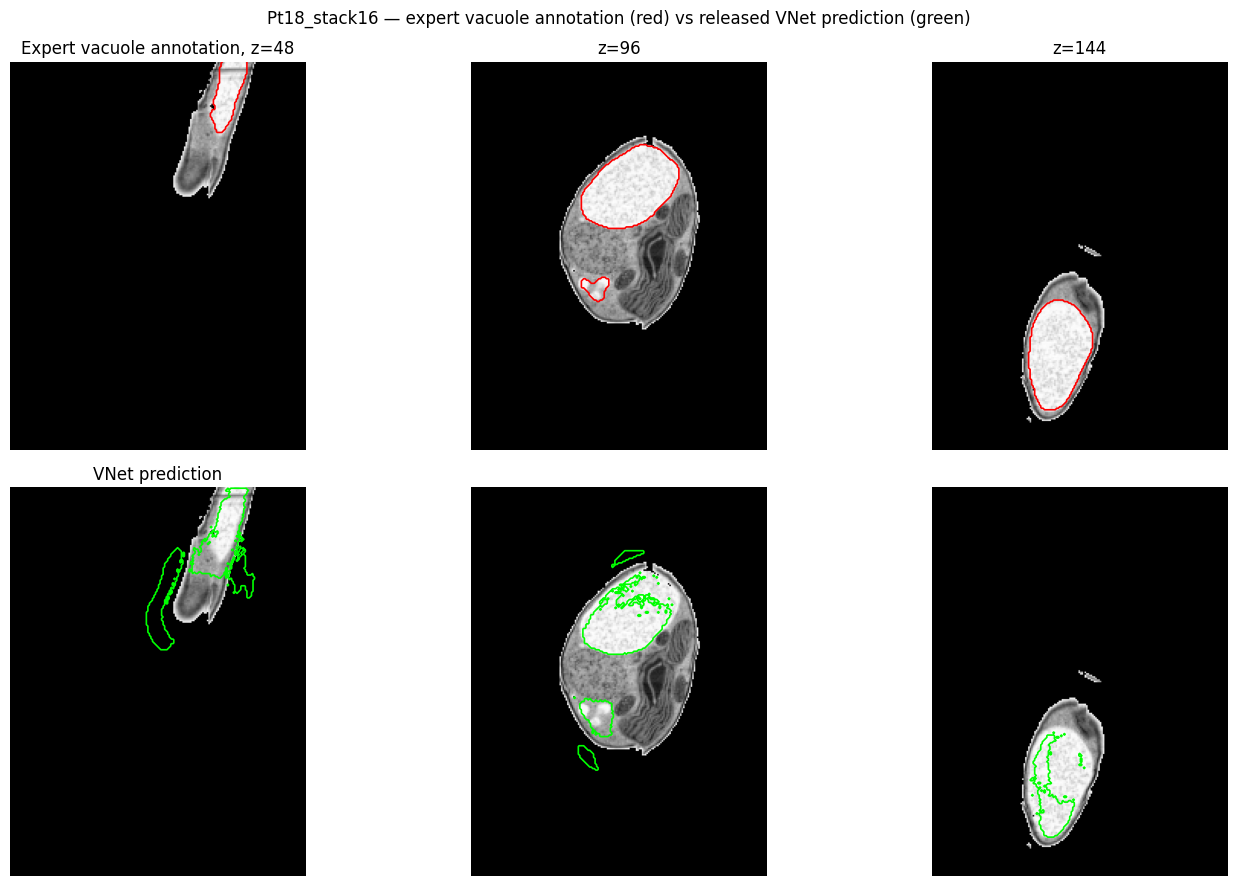

In [ ]:
# @title 11. Overlay expert vacuole annotation and VNet prediction on input slices
zs = sorted({img.shape[0] // 4, img.shape[0] // 2, (3 * img.shape[0]) // 4})
fig, axes = plt.subplots(2, len(zs), figsize=(5 * len(zs), 9))
for j, z in enumerate(zs):
    axes[0, j].imshow(img[z].T, cmap="gray", origin="lower")
    axes[0, j].contour(msk_vac_c[z].T, levels=[0.5], colors="red", linewidths=1.2, origin="lower")
    axes[0, j].set_title(f"Expert vacuole annotation, z={z}" if j == 0 else f"z={z}")
    axes[1, j].imshow(img[z].T, cmap="gray", origin="lower")
    axes[1, j].contour(pred_c[z].T, levels=[0.5], colors="lime", linewidths=1.2, origin="lower")
    axes[1, j].set_title("VNet prediction" if j == 0 else "")
    for r in range(2):
        axes[r, j].axis("off")
fig.suptitle("Pt18_stack16 — expert vacuole annotation (red) vs released VNet prediction (green)")
plt.tight_layout(); plt.show()

### 12. Results table and CSV export

A small summary of the measured values (primary demonstration + sensitivity rows), with runtime context. The CSV is written inside the Colab VM.

測定結果の表と CSV 出力です。

In [ ]:
# @title 12. Summarize results and export CSV
rows = [{"recipe": "primary: raw stack + pad/32", "checkpoint": "vacuole full-cell pt18", "metric": m, "value": v}
        for m, v in [("Dice", dice_v), ("IoU", iou_v), ("precision", prec_v), ("recall", rec_v), ("F1", f1_v)]]
rows += [{"recipe": r["input"] + " input", "checkpoint": r["checkpoint"], "metric": "Dice", "value": r["Dice"]}
         for r in sensitivity]
results = pd.DataFrame(rows)
results.to_csv("/content/morpholearn/vnet_pt18_stack16_metrics.csv", index=False)
print(results.to_string(index=False))
print("runtime:", device.type, "| stack16 shape:", stack.shape,
      "| primary inference: {:.1f} s".format(elapsed))
print("CSV saved to /content/morpholearn/vnet_pt18_stack16_metrics.csv")

                     recipe             checkpoint    metric    value
primary: raw stack + pad/32 vacuole full-cell pt18      Dice 0.670767
primary: raw stack + pad/32 vacuole full-cell pt18       IoU 0.504627
primary: raw stack + pad/32 vacuole full-cell pt18 precision 0.726519
primary: raw stack + pad/32 vacuole full-cell pt18    recall 0.622961
primary: raw stack + pad/32 vacuole full-cell pt18        F1 0.670767
                  raw input           vacuole ckpt      Dice 0.670800
       2x downsampled input           vacuole ckpt      Dice 0.412400
       4x downsampled input           vacuole ckpt      Dice 0.100500
                  raw input       chloroplast ckpt      Dice 0.374000
       2x downsampled input       chloroplast ckpt      Dice 0.364800
       4x downsampled input       chloroplast ckpt      Dice 0.291300
runtime: cpu | stack16 shape: (192, 194, 255) | primary inference: 41.3 s
CSV saved to /content/morpholearn/vnet_pt18_stack16_metrics.csv


## Interpretation, differences from the paper, and validation record

**What was executed:** released `best_model_vacuole_fullcell_pt18_Vnet.pth` inference on one *P. tricornutum* strain-18 FIB-SEM stack (`Pt18_stack16.nii`) with its expert vacuole mask (`labels_vacuole/Pt18_Segmentation16.nii`), scored with the authors' verbatim Dice/IoU/precision/recall/F1, plus a labeled sensitivity analysis (input scaling; chloroplast checkpoint).

**Known limitations (all recorded, none hidden):**
1. The paper's methods text was not readable at authoring time (ScienceDirect JavaScript body; HAL deposit behind an anti-bot challenge; no PMC/OpenAlex copy), so the **exact full-cell training recipe and train/test split are unverified**. The raw-input recipe is inferred from the checkpoints' observed behaviour and is labeled as an assumption; sensitivity rows quantify the alternatives.
2. **The split is unknown** — `Pt18_stack16.nii` may have been part of the model's training data. These numbers are a *demonstration*, not held-out validation and not a reproduction of the paper's reported accuracies.
3. **Unresolved discrepancy:** the released chloroplast checkpoint over-predicts chloroplast voxels by 3–4× relative to the expert masks on the stacks we tested, under every candidate recipe; cause unverifiable without the methods text.
4. Single-example scope: no benchmark, no other strains/targets/architectures; the checkpoint's training configuration (epochs, augmentation, loss weights) is not in the released scripts and was not inferred.

**References**
- Uwizeye et al. (2026), Cell Reports Methods, DOI 10.1016/j.crmeth.2026.101594.
- MorphoLearn @ `0fba3a0f49ce59f95853fad01580a246d3c7c274`, MIT License — `3DVnet/model_Vnet_4.py`, `3DVnet/cross_validation_VNet.py`, `3DVnet/dataset_patches.py`.
- BioImage Archive S-BIAD2407 (CC0), DOI 10.6019/S-BIAD2407.

**検証の範囲と限界:** 単一スタックでの事前学習済み推論の実演です。前処理のレシピと学習/テスト分割は未検証であり、論文の報告値の再現ではありません。